In [1]:
import numpy as np
from pathlib import Path
import pandas as pd
import sys
sys.path.insert(1, '../../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter, OS_model, k_risk

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc
import seaborn as sns

font = {'size':10}
mpl.rc('font', **font)

### Data_processing to get to df_TEs, T_lims, betas, q_c, q_r and the interaction matrices A

In [2]:
%run Data_processing.py

# Simulations

## Baseline

In [4]:
baselines  = ['ssp119', 'ssp534-over', 'CurPol_OS_1.5C']
temps = [df[b].to_numpy() for b in baselines]

In [6]:
### BASELINE SIMULATIONS
D_bs = []
for temp in temps:
    years = np.arange(1850,1850+len(temp))
    no_years = len(years)
    # Modifying collapse probabilities for each year according to each scenario
    p_c = np.ones((no_years,len(df_TEs)))
    p_c *= q_c
    
    p_r = np.ones((no_years,len(df_TEs)))
    p_r *= q_r
    
    for t in range(no_years):
        p_c[t,:] *= temp_response(temp[t], T_lim, betas)
        p_r[t,:] *= (1-temp_response(temp[t], T_lim, betas))
    
    D_baseline = np.zeros((len_sample,len(df_TEs),no_years))
    for r in range(len_sample):
        for t in range(1,no_years):
            D_baseline[r,:,t] = environmental_update(D_baseline[r,:,t-1],A[r],pc=p_c[t,:],pr=p_r[t,:])
    D_bs.append(D_baseline)

In [8]:
D_bs[0].shape

(500, 9, 451)

In [9]:
TR_bs = []
for D in D_bs:
    d_nr = np.delete(D,6,axis=1)
    TR_bs.append(k_risk(d_nr,1,axis=1))

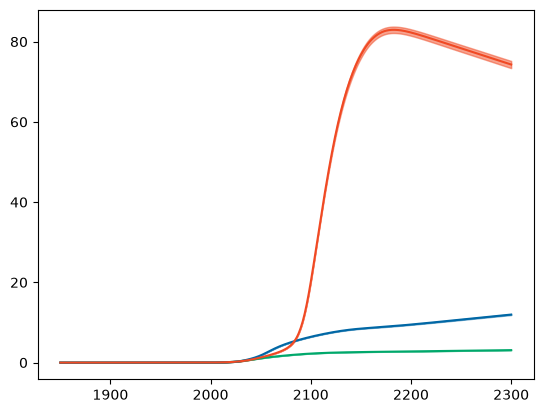

In [18]:
fig,ax=plt.subplots()
colors = ['#00A86B', '#0067A5', '#F04923']
for i in range(3):
    ax.fill_between(years,
                    (TR_bs[i].mean(axis=0)-TR_bs[i].std(axis=0))*100, 
                    (TR_bs[i].mean(axis=0)+TR_bs[i].std(axis=0))*100, color=colors[i],alpha=0.5)
    ax.plot(years,TR_bs[i].mean(axis=0)*100,color=colors[i])

In [21]:
for i in range(3):
    print(str(100*TR_bs[i][:,-1].mean()) + r'$\pm$' + str(100*TR_bs[i][:,-1].std()))

3.108357814481343$\pm$0.009286389308956169
11.972337966238$\pm$0.11819361659932065
74.29908566487352$\pm$0.898797070829108


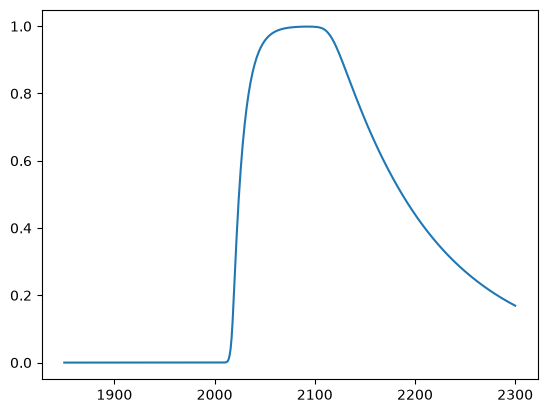

In [13]:
plt.plot(years,D_bs[0].mean(axis=0)[6])

## Ensemble

In [3]:
folder = '../../../Data/PROVIDE 2025/fair_temperatures/'
scenarios = os.listdir(folder)
print(scenarios)

['scen_CurPol nz 2120 decline -23800.csv', 'scen_CurPol.csv', 'scen_GS.csv', 'scen_GS_NZGHG.csv', 'scen_LD.csv', 'scen_LD_NZGHG.csv', 'scen_ModAct nz 2120 decline -16500.csv', 'scen_ModAct nz 2120 decline -23000.csv', 'scen_ModAct.csv', 'scen_Neg nz 2100 decline -17000.csv', 'scen_Neg.csv', 'scen_Neg_NZGHG.csv', 'scen_Ref_1p5.csv', 'scen_Ren.csv', 'scen_Ren_NZCO2.csv', 'scen_SP.csv', 'scen_SP_NZGHG.csv', 'scen_ssp119.csv', 'scen_ssp534-over.csv']


In [18]:
baselines = ['ssp119','ssp534-over','CurPol nz 2120 decline -23800']
temps = [pd.read_csv(folder+'scen_%s.csv'%baseline).set_index('year').to_numpy().T for baseline in baselines]

In [20]:
pcs = [np.ones(list(temps[k].shape)+[len(df_TEs)])*q_c.reshape((1,1,len(df_TEs))) for k in range(3)]
prs = [np.ones(list(temps[k].shape)+[len(df_TEs)])*q_r.reshape((1,1,len(df_TEs))) for k in range(3)]

for k in range(3):
    no_runs, no_years = temps[k].shape
    sigma = temp_response(temps[k].reshape(no_runs, no_years,1),
                          T_lim.reshape(1,1,9),
                          betas.reshape(1,1,9))
    pcs[k] *= sigma
    prs[k] *= 1-sigma

Given the number of samples across interaction matrices (500) AND the number of ensemble runs (2237),

we find it better to save only summary statistics (across 500x2237 flattened) namely:
- mean
- std
- median
- 0.1 / 0.9 quantile
- 0.25 / 0.75 quantile

In [51]:
k = 0

D_mean = np.zeros([temps[k].shape[1],len(df_TEs)])
D_std = np.zeros([temps[k].shape[1],len(df_TEs)])
D_quants = np.zeros([5, temps[k].shape[1],len(df_TEs)]) # [0.1,0.25,0.5,0.75,0.9] quantiles
no_runs, no_years = temps[k].shape
D_t = np.zeros([500,no_runs,9]) # snapshots of D
for t in tqdm.tqdm(range(no_years)):
    D_mean[t,:] = D_t.mean(axis=(0,1)) # saving mean
    D_std[t,:] = D_t.std(axis=(0,1)) # saving std
    D_quants[:,t,:] = np.quantile(D_t, [0.1,0.25,0.5,0.75,0.9],axis=(0,1))
    
    for er in range(no_runs):
        for r in range(500):
            D_t[r,er,:] = environmental_update(D_t[r,er,:],A[r],
                                               pc=pcs[k][er,t,:],
                                               pr=prs[k][er,t,:])

100%|██████████████████████████████████████████████████████████████████████████████| 451/451 [2:05:04<00:00, 16.64s/it]


In [54]:
data_folder = '../../../Data/Simulations/Overshoots/'
if k<2:
    data_folder += baselines[k]+'/'
else:
    data_folder += 'CurPol-OS-1.5C/'

data_folder += 'Ensemble/'
if not os.path.isdir(data_folder):
    os.mkdir(data_folder)

np.savetxt(data_folder+'mean.csv',D_mean)
np.savetxt(data_folder+'std.csv',D_std)
for i,p in enumerate([10,25,50,75,90]):
    np.savetxt(data_folder+'q%s.csv'%p,D_quants[i,:,:])